In [43]:
pip install openpyxl seaborn


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [44]:
# importing the libraries 
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split ,GridSearchCV ,TimeSeriesSplit, cross_validate
from sklearn.preprocessing import StandardScaler ,PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping




In [45]:
#loding the dataset 
df = pd.read_excel('Folds5x2_pp.xlsx')
df.head(10)

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90
5,26.27,59.44,1012.23,58.77,443.67
6,15.89,43.96,1014.02,75.24,467.35
7,9.48,44.71,1019.12,66.43,478.42
8,14.64,45.00,1021.78,41.25,475.98
9,11.74,43.56,1015.14,70.72,477.50


In [46]:
df.shape

(9568, 5)

In [47]:
print(df.info())
print(df.isnull().sum())
print(df.describe())
print(df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
 4   PE      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB
None
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64
                AT            V           AP           RH           PE
count  9568.000000  9568.000000  9568.000000  9568.000000  9568.000000
mean     19.651231    54.305804  1013.259078    73.308978   454.365009
std       7.452473    12.707893     5.938784    14.600269    17.066995
min       1.810000    25.360000   992.890000    25.560000   420.260000
25%      13.510000    41.740000  1009.100000    63.327500   439.750000
50%      20.345000    52.080000  1012.940000    74.975000   451.550000
75%      25.720000    66.540000  1017.260000    8

In [48]:
skewness = df.skew(numeric_only=True)

print(skewness.sort_values())

RH   -0.431839
AT   -0.136393
V     0.198521
AP    0.265445
PE    0.306509
dtype: float64


PE    1.000000
AP    0.518429
RH    0.389794
V    -0.869780
AT   -0.948128
Name: PE, dtype: float64


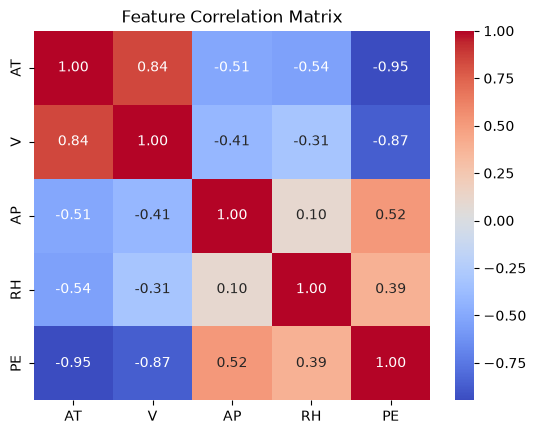

In [49]:


correlations = df.corr(numeric_only=True)

print(correlations["PE"].sort_values(ascending=False))

sns.heatmap(correlations, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.show()

In [50]:
# features and target 
Y = df['PE']
X = df.drop(columns="PE")

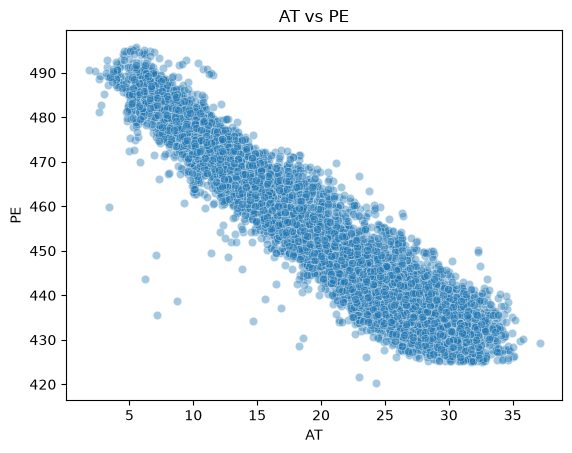

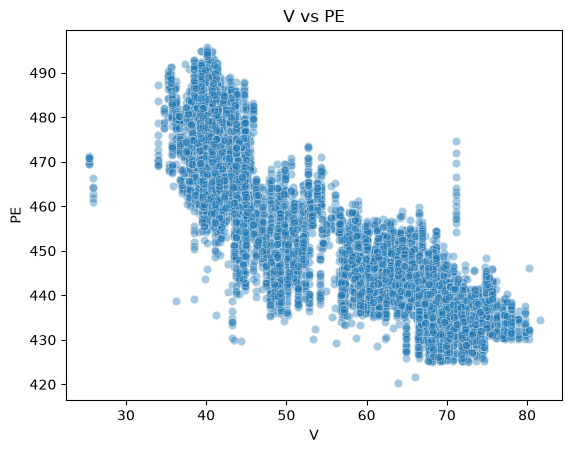

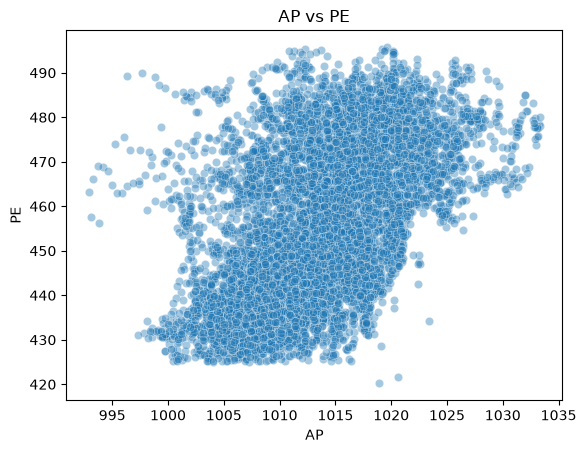

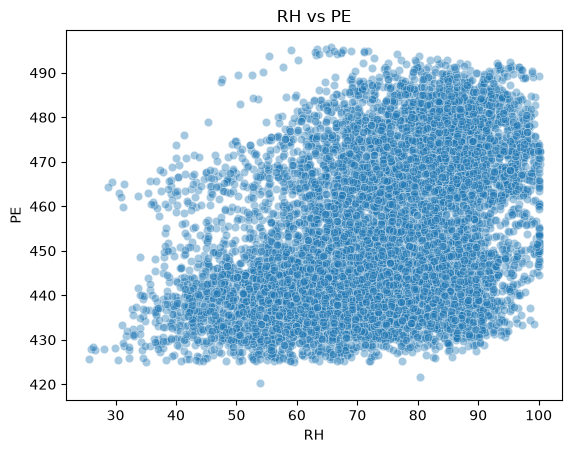

In [51]:
for feature in X.columns:
    sns.scatterplot(data=df, x=feature, y="PE", alpha=0.4)
    plt.title(f"{feature} vs PE")
    plt.show()

In [52]:
#splitting the data set 
X_train ,X_test ,Y_train ,Y_test =train_test_split(X,Y ,test_size=0.3,shuffle=False)

In [53]:
#creating a baseline pipeline 
baseline_model =Pipeline([('scaler',StandardScaler()),
                          ("model",LinearRegression())])
#training the model 
baseline_model.fit(X_train,Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['AT','V','AP','RH']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [54]:
poly_model = Pipeline([
    ("poly", PolynomialFeatures(include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

param_grid = {
    "poly__degree": [1, 2, 3]
}

grid = GridSearchCV(
    poly_model,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, Y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'poly__degree': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed du

In [55]:
print("Best parameters:", grid.best_params_)
print("Best CV MAE:", -grid.best_score_)


Best parameters: {'poly__degree': 3}
Best CV MAE: 3.2192602864978936


In [56]:
#Initialize the model
dt_model = Pipeline([('scaler',StandardScaler()),
                     ('model',DecisionTreeRegressor(random_state=42))])

# Train
dt_model.fit(X_train, Y_train)



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['AT','V','AP','RH']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [57]:

# Pipeline
pipeline = Pipeline([('Scaler',StandardScaler()),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("model", DecisionTreeRegressor(random_state=42))
])

# Hyperparameter grid
param_grid = {
    "poly__degree": [1, 2, 3],
    "model__criterion": ["squared_error", "friedman_mse", "absolute_error"],
    "model__max_depth": [3, 5, 8, 10, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__max_features": [None, "sqrt", 0.8]
}

# Use chronological CV if your row order represents time
tscv = TimeSeriesSplit(n_splits=5)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    n_jobs=-1,
    verbose=1
)

# Fit only on training data
grid_search.fit(X_train, Y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("Best CV RMSE:", -grid_search.best_score_)

Fitting 5 folds for each of 1620 candidates, totalling 8100 fits
Best parameters:
{'model__criterion': 'squared_error', 'model__max_depth': 8, 'model__max_features': 0.8, 'model__min_samples_leaf': 10, 'model__min_samples_split': 2, 'poly__degree': 1}
Best CV RMSE: 4.312534655363814


/home/kirema/projects.../project/lib/python3.14/site-packages/sklearn/model_selection/_validation.py:493: FitFailedWarning: 
2700 fits failed out of a total of 8100.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
338 fits failed with the following error:
Traceback (most recent call last):
  File "/home/kirema/projects.../project/lib/python3.14/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/kirema/projects.../project/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/home/kirema/projects.../project/lib/python3.14/s

In [58]:

# Generate predictions from the correct fitted models
baseline_pred = baseline_model.predict(X_test)

poly_pred = grid.predict(X_test)

dt_pred = dt_model.predict(X_test)

tuned_dt_pred = grid_search.best_estimator_.predict(X_test)

# Evaluate each model using its OWN predictions
models = [
    ("Baseline Linear Regression", baseline_pred),
    ("Polynomial Regression", poly_pred),
    ("Decision Tree", dt_pred),
    ("Tuned Polynomial Decision Tree", tuned_dt_pred)
]

results = []

for name, predictions in models:
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(Y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(Y_test, predictions)),
        "R2": r2_score(Y_test, predictions)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))


                         Model    MAE   RMSE     R2
    Baseline Linear Regression 3.7051 4.7128 0.9243
         Polynomial Regression 3.2957 4.2900 0.9373
                 Decision Tree 3.1476 4.6170 0.9274
Tuned Polynomial Decision Tree 3.0354 4.1245 0.9420


In [59]:
#creating a mlp 
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32,activation='relu'),
    Dense(16,activation='relu'),
    Dense(1,activation='linear')
])

In [60]:
#compiling the model
model.compile(
    optimizer=Adam(learning_rate=0.005),
    loss="mse",
    metrics=["mae"]
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705 (2.75 KB)

 Trainable params: 705 (2.75 KB)

 Non-trainable params: 0 (0.00 B)

In [61]:
#training the model 
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    Y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 108841.2969 - mae: 293.0962 - val_loss: 12856.4746 - val_mae: 95.5211
Epoch 2/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5267.7817 - mae: 57.9725 - val_loss: 1490.7845 - val_mae: 31.0724
Epoch 3/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 824.1844 - mae: 22.2431 - val_loss: 437.0276 - val_mae: 16.2843
Epoch 4/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 284.6151 - mae: 12.8079 - val_loss: 185.3545 - val_mae: 10.8040
Epoch 5/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 129.0015 - mae: 8.6117 - val_loss: 90.2767 - val_mae: 7.3742
Epoch 6/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 71.9600 - mae: 6.3410 - val_loss: 55.4383 - val_mae: 5.6278
Epoch 7/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 47.6565 - mae: 5.1548 - val_loss: 40.2489 - val_mae: 4.7931
Epoch 8/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 36.3230 - mae: 4.5124 - val_loss: 32.0306 - val_mae: 4.3362
Epoch 9

In [62]:
#evaluating the model 
y_pred = model.predict(X_test).ravel()

mae = mean_absolute_error(Y_test, y_pred)
rmse = np.sqrt(mean_squared_error(Y_test, y_pred))
r2 = r2_score(Y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
MAE: 3.510958984545074
RMSE: 4.525277816901205
R2: 0.930217827662006


In [63]:
cv_results = cross_validate(
    grid_search.best_estimator_,
    X,
    Y,
    cv=tscv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    return_train_score=True,
    n_jobs=-1
)

results = pd.DataFrame({
    "Fold": range(1, 6),
    "Train MAE": -cv_results["train_mae"],
    "Validation MAE": -cv_results["test_mae"],
    "Train RMSE": -cv_results["train_rmse"],
    "Validation RMSE": -cv_results["test_rmse"],
    "Validation R2": cv_results["test_r2"]
})

print(results.round(4))
print("\nMean validation metrics:")
print(results[[
    "Validation MAE",
    "Validation RMSE",
    "Validation R2"
]].mean().round(4))

   Fold  Train MAE  Validation MAE  Train RMSE  Validation RMSE  Validation R2
0     1     2.6905          3.4594      3.4820           4.6144         0.9262
1     2     2.7305          3.1692      3.6033           4.2262         0.9392
2     3     2.6781          3.0658      3.5575           3.9465         0.9462
3     4     2.7646          3.0553      3.6547           4.2114         0.9418
4     5     2.7152          2.9837      3.6417           4.0045         0.9434

Mean validation metrics:
Validation MAE     3.1467
Validation RMSE    4.2006
Validation R2      0.9394
dtype: float64


In [64]:
import numpy as np

y_pred = grid_search.best_estimator_.predict(X_test)

print("y_test shape:", np.asarray(Y_test).shape)
print("y_pred shape:", y_pred.shape)

print("\nActual target:")
print("Min:", np.min(Y_test))
print("Max:", np.max(Y_test))
print("Mean:", np.mean(Y_test))

print("\nPredictions:")
print("Min:", np.min(y_pred))
print("Max:", np.max(y_pred))
print("Mean:", np.mean(y_pred))

print("\nFirst 5 actual values:")
print(np.asarray(Y_test)[:5])

print("\nFirst 5 predictions:")
print(y_pred[:5])

y_test shape: (2871,)
y_pred shape: (2871,)

Actual target:
Min: 420.26
Max: 495.23
Mean: 454.2647300592128

Predictions:
Min: 491.5430769230769
Max: 491.5430769230769
Mean: 491.54307692307697

First 5 actual values:
[481.08 425.21 427.01 450.86 469.63]

First 5 predictions:
[491.54307692 491.54307692 491.54307692 491.54307692 491.54307692]


/home/kirema/projects.../project/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


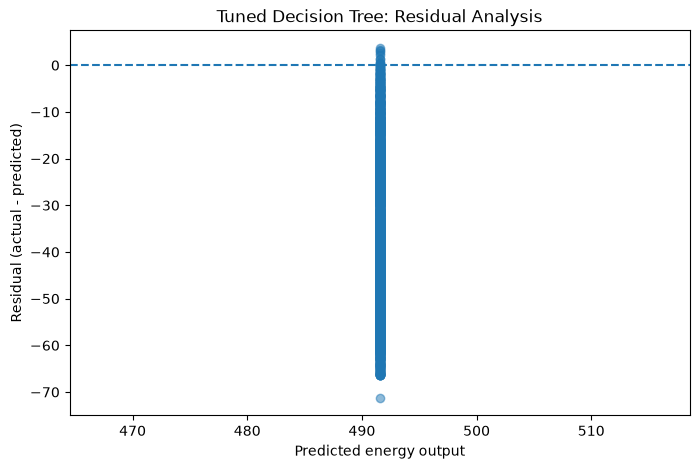

In [65]:

residuals = np.asarray(Y_test) - np.asarray(y_pred)

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted energy output")
plt.ylabel("Residual (actual - predicted)")
plt.title("Tuned Decision Tree: Residual Analysis")
plt.show()

In [66]:
best_pipeline = grid_search.best_estimator_

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest CV RMSE:")
print(-grid_search.best_score_)

print("\nPipeline:")
print(best_pipeline)

tree = best_pipeline.named_steps["model"]

print("\nTree depth:", tree.get_depth())
print("Number of leaves:", tree.get_n_leaves())
print("Number of nodes:", tree.tree_.node_count)
print("Training target standard deviation:", np.std(Y_train))

Best parameters:
{'model__criterion': 'squared_error', 'model__max_depth': 8, 'model__max_features': 0.8, 'model__min_samples_leaf': 10, 'model__min_samples_split': 2, 'poly__degree': 1}

Best CV RMSE:
4.312534655363814

Pipeline:
Pipeline(steps=[('Scaler', StandardScaler()),
                ('poly', PolynomialFeatures(degree=1, include_bias=False)),
                ('model',
                 DecisionTreeRegressor(max_depth=8, max_features=0.8,
                                       min_samples_leaf=10, random_state=42))])

Tree depth: 8
Number of leaves: 201
Number of nodes: 401
Training target standard deviation: 17.038190496708257


In [67]:
X_train_scaled = best_pipeline.named_steps["Scaler"].transform(X_train)

X_train_poly = best_pipeline.named_steps["poly"].transform(
    X_train_scaled
)

print("Scaled features unique rows:",
      np.unique(X_train_scaled, axis=0).shape[0])

print("Polynomial features shape:", X_train_poly.shape)

print("Polynomial unique rows:",
      np.unique(X_train_poly, axis=0).shape[0])

print("First 5 transformed rows:")
print(X_train_poly[:5])

Scaled features unique rows: 6677
Polynomial features shape: (6697, 4)
Polynomial unique rows: 6677
First 5 transformed rows:
[[  -2.72546829   -4.35889731 -170.33826211   -5.03163923]
 [  -2.54040045   -4.22694791 -170.45254696   -5.09801114]
 [  -2.90383603   -4.37358601 -170.67601214   -4.94227974]
 [  -2.61862874   -4.26205143 -170.73046051   -5.01529356]
 [  -2.80043707   -4.38541167 -170.75910262   -4.9211764 ]]


/home/kirema/projects.../project/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [68]:
train_pred = best_pipeline.predict(X_train)
test_pred = best_pipeline.predict(X_test)

print("Unique training predictions:",
      np.unique(train_pred).size)

print("Unique test predictions:",
      np.unique(test_pred).size)

print("Training prediction range:",
      train_pred.min(), train_pred.max())

print("Test prediction range:",
      test_pred.min(), test_pred.max())

Unique training predictions: 1
Unique test predictions: 1
Training prediction range: 491.5430769230769 491.5430769230769
Test prediction range: 491.5430769230769 491.5430769230769


/home/kirema/projects.../project/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/home/kirema/projects.../project/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [69]:
best_pipeline = grid_search.best_estimator_
tree = best_pipeline.named_steps["model"]

print("Best parameters:", grid_search.best_params_)
print("Best CV RMSE:", -grid_search.best_score_)

print("Tree depth:", tree.get_depth())
print("Tree leaves:", tree.get_n_leaves())
print("Tree nodes:", tree.tree_.node_count)

print("Mean y_train:", np.mean(Y_train))
print("Unique y_train:", np.unique(Y_train).size)

print("Tree node values:")
print(tree.tree_.value[:10].ravel())

Best parameters: {'model__criterion': 'squared_error', 'model__max_depth': 8, 'model__max_features': 0.8, 'model__min_samples_leaf': 10, 'model__min_samples_split': 2, 'poly__degree': 1}
Best CV RMSE: 4.312534655363814
Tree depth: 8
Tree leaves: 201
Tree nodes: 401
Mean y_train: 454.40799910407645
Unique y_train: 4061
Tree node values:
[454.4079991  471.16161324 479.18784161 479.80541935 484.09764835
 486.11784141 488.37       489.30673077 491.54307692 488.56128205]


In [70]:
# Get predictions from the fitted GridSearchCV model
y_pred_check = grid_search.predict(X_test)

print("Best estimator:")
print(grid_search.best_estimator_)

print("\nPrediction diagnostics:")
print("First 10 predictions:", y_pred_check[:10])
print("Unique predictions:", len(np.unique(y_pred_check)))
print("Prediction min:", y_pred_check.min())
print("Prediction max:", y_pred_check.max())

print("\nRecomputed test metrics:")
print("MAE:", mean_absolute_error(Y_test, y_pred_check))
print("RMSE:", np.sqrt(mean_squared_error(Y_test, y_pred_check)))
print("R²:", r2_score(Y_test, y_pred_check))

Best estimator:
Pipeline(steps=[('Scaler', StandardScaler()),
                ('poly', PolynomialFeatures(degree=1, include_bias=False)),
                ('model',
                 DecisionTreeRegressor(max_depth=8, max_features=0.8,
                                       min_samples_leaf=10, random_state=42))])

Prediction diagnostics:
First 10 predictions: [491.54307692 491.54307692 491.54307692 491.54307692 491.54307692
 491.54307692 491.54307692 491.54307692 491.54307692 491.54307692]
Unique predictions: 1
Prediction min: 491.5430769230769
Prediction max: 491.5430769230769

Recomputed test metrics:
MAE: 37.29179594352007
RMSE: 41.026006167071294
R²: -4.735515709674517


/home/kirema/projects.../project/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [71]:
print("X_train type:", type(X_train))
print("X_test type:", type(X_test))

print("\nX_train columns:")
print(getattr(X_train, "columns", "No column names"))

print("\nX_test columns:")
print(getattr(X_test, "columns", "No column names"))

print("\nX_test first 5 rows:")
print(X_test[:5] if isinstance(X_test, np.ndarray) else X_test.head())

X_train type: <class 'numpy.ndarray'>
X_test type: <class 'numpy.ndarray'>

X_train columns:
No column names

X_test columns:
No column names

X_test first 5 rows:
[[-1.39892241 -1.33364435  0.28448116 -0.40648421]
 [ 1.42295708  1.38735828 -0.85390213 -0.97477027]
 [ 1.24263669  1.49228532 -0.14493857 -0.30902452]
 [ 0.86450215 -0.63544564 -0.33859845 -1.23900956]
 [-0.29143227 -0.93444825 -0.73265421 -0.28225742]]


In [72]:
# Fit the existing GridSearchCV pipeline on the rebuilt training data
grid_search.best_estimator_.fit(X_train, Y_train)

# Generate fresh predictions
y_pred = grid_search.best_estimator_.predict(X_test)

In [73]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Unique predictions:", len(np.unique(y_pred)))
print("First 10 predictions:", y_pred[:10])

print("\nEvaluation Metrics")
print("MAE:", mean_absolute_error(Y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(Y_test, y_pred)))
print("R²:", r2_score(Y_test, y_pred))

Unique predictions: 201
First 10 predictions: [482.5        431.62632184 434.53137097 446.19228571 462.438
 446.19228571 432.16885246 477.81455959 431.62632184 452.1875    ]

Evaluation Metrics
MAE: 3.0353855716030522
RMSE: 4.12447930702709
R²: 0.9420314750239606
